# PathSnap EDA and preprocessing audit

This notebook summarizes the generated preprocessing statistics, checks raw-file completeness, plots three GPS tracks, and overlays one GPS track with its reference route. Run it from the `pathsnap/` project directory after `python -m src.features train` and `python -m src.features student_test`.

In [1]:
# Colab opens this notebook without checking out the repository's data files.
from pathlib import Path
import os, subprocess

REPO_URL = 'https://github.com/diya-jm/Pathsnap-map-matching.git'
cwd = Path.cwd()
candidates = [cwd, cwd / 'pathsnap', cwd / 'Pathsnap-map-matching' / 'pathsnap']
project_dir = next((p for p in candidates if (p / 'results/prep_stats_train.csv').exists() and (p / 'data/raw').exists()), None)
if project_dir is None:
    repo_dir = cwd / 'Pathsnap-map-matching'
    if not repo_dir.exists():
        subprocess.run(['git', 'clone', REPO_URL, str(repo_dir)], check=True)
    project_dir = repo_dir / 'pathsnap'
if not (project_dir / 'results/prep_stats_train.csv').exists():
    raise FileNotFoundError(f'Could not find project data under {project_dir}')
os.chdir(project_dir)
print(f'Using project folder: {project_dir.resolve()}')

Using project folder: C:\Users\jithu\pathsnap\pathsnap


## 1. Load and summarize preprocessing statistics

`n_pts` is the number of GPS observations retained by preprocessing. `mean_cand` is the average number of nearby road-arc candidates per observation. `pts_no_cand` counts observations without any candidate road arc. `miss_rate` counts observations without a positive candidate label along the available reference route. The student-test split also has route files in this project, so its label-miss rate is a preprocessing diagnostic, not an official model-accuracy score.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path('.')
train = pd.read_csv(ROOT / 'results/prep_stats_train.csv', dtype={'trip': str})
student = pd.read_csv(ROOT / 'results/prep_stats_student_test.csv', dtype={'trip': str})

def split_summary(df, name):
    pts = df['n_pts'].sum()
    # Recover candidate totals from per-trip candidate means, then weight by points.
    mean_candidates = (df['mean_cand'] * df['n_pts']).sum() / pts
    weighted_miss = (df['miss_rate'] * df['n_pts']).sum() / pts
    return {'split': name, 'trips': len(df), 'GPS points': pts,
            'mean points/trip': df['n_pts'].mean(),
            'mean candidates/point (weighted)': mean_candidates,
            'points with no candidate': df['pts_no_cand'].sum(),
            'label miss rate (weighted)': weighted_miss}

summary = pd.DataFrame([split_summary(train, 'train'), split_summary(student, 'student_test')])
display(summary.round(3))
display(train.sort_values('miss_rate', ascending=False).head(10).round(3))
display(student.round(3))

,split,trips,GPS points,mean points/trip,mean candidates/point (weighted),points with no candidate,label miss rate (weighted)
0,train,80,208417,2605.212,11.111,17492,0.142
1,student_test,10,19160,1916.000,13.816,0,0.084


,trip,n_pts,arcs_kept,mean_cand,pts_no_cand,candidate_miss_pts,miss_rate
44,00000054,19313,101022,3.265,16178,17211,0.891
26,00000033,5844,3644,12.363,32,3966,0.679
20,00000026,361,2267,13.335,0,155,0.429
5,00000006,1450,4349,13.957,0,556,0.383
49,00000061,1430,7069,48.725,0,451,0.315
75,00000095,1551,2290,17.259,0,464,0.299
68,00000085,1092,1232,8.614,0,268,0.245
71,00000089,1228,21111,33.232,0,301,0.245
6,00000008,3093,4300,16.411,0,616,0.199
32,00000039,363,1630,8.025,0,71,0.196


,trip,n_pts,arcs_kept,mean_cand,pts_no_cand,candidate_miss_pts,miss_rate
0,00000000,2503,15579,6.417,0,0,0.000
1,00000007,1354,2689,4.442,0,0,0.000
2,00000009,1049,8773,24.602,0,35,0.033
3,00000040,2995,22459,6.330,0,0,0.000
4,00000052,262,1735,11.767,0,0,0.000
5,00000056,3958,17176,15.751,0,782,0.198
6,00000065,768,9084,18.686,0,96,0.125
7,00000076,1486,46585,26.176,0,0,0.000
8,00000077,3911,8008,15.793,0,696,0.178
9,00000091,874,7657,19.945,0,0,0.000


## 2. Raw dataset completeness

Each trip should have a `.track`, `.route`, `.nodes`, and `.arcs` file. This check reports missing files and raw track rows containing null fields; it does not infer why a file or observation is missing.

In [3]:
from src.load import ROOT as DATA_ROOT

required = ['track', 'route', 'nodes', 'arcs']
checks = []
for split in ['train', 'student_test']:
    split_dir = Path(DATA_ROOT) / split
    for trip_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        tid = trip_dir.name
        missing = [ext for ext in required if not (trip_dir / f'{tid}.{ext}').exists()]
        raw_track = pd.read_csv(trip_dir / f'{tid}.track', sep=r'\s+', header=None, names=['lon', 'lat', 't']) if 'track' not in missing else pd.DataFrame()
        checks.append({'split': split, 'trip': tid, 'missing files': ', '.join(missing) or 'none',
                       'raw track rows': len(raw_track),
                       'raw rows with any null': int(raw_track.isna().any(axis=1).sum()) if len(raw_track) else np.nan})
completeness = pd.DataFrame(checks)
display(completeness.query("`missing files` != 'none' or `raw rows with any null` > 0"))
print(f'{len(completeness)} trip folders checked; {completeness["missing files"].ne("none").sum()} have missing required files; {(completeness["raw rows with any null"] > 0).sum()} have null track rows.')

# Focused audit of trip 57: compare raw row count and timestamp range.
trip57 = completeness.query("split == 'train' and trip == '00000057'").iloc[0]
print('Trip 57 current raw-file audit:', trip57.to_dict())
raw57 = pd.read_csv(Path(DATA_ROOT) / 'train/00000057/00000057.track', sep=r'\s+', header=None, names=['lon', 'lat', 't'])
print('Trip 57 timestamp span:', raw57['t'].min(), 'to', raw57['t'].max(), '; observed rows:', len(raw57), '; missing integer timestamps in span:', len(set(range(int(raw57.t.min()), int(raw57.t.max()) + 1)) - set(raw57.t.astype(int))))

,split,trip,missing files,raw track rows,raw rows with any null


90 trip folders checked; 0 have missing required files; 0 have null track rows.
Trip 57 current raw-file audit: {'split': 'train', 'trip': '00000057', 'missing files': 'none', 'raw track rows': 1645, 'raw rows with any null': 0}
Trip 57 timestamp span: 1.0 to 1670.0 ; observed rows: 1645 ; missing integer timestamps in span: 25


## 3. GPS track shapes

These tracks are drawn in longitude/latitude coordinates. The plot is for visual inspection; distances and candidate search in the feature pipeline use projected coordinates.

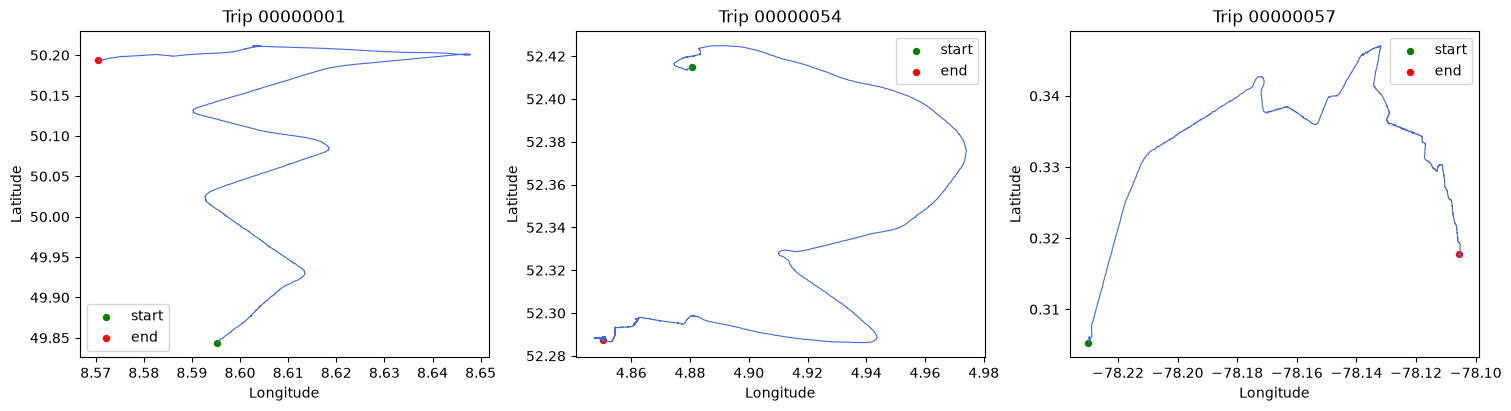

In [4]:
import matplotlib.pyplot as plt
from src.load import load_trip

example_ids = ['00000001', '00000054', '00000057']
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, tid in zip(axes, example_ids):
    trk, _, _, _ = load_trip('train', tid)
    ax.plot(trk.lon, trk.lat, linewidth=0.8, color='royalblue')
    ax.scatter(trk.lon.iloc[0], trk.lat.iloc[0], s=18, color='green', label='start')
    ax.scatter(trk.lon.iloc[-1], trk.lat.iloc[-1], s=18, color='red', label='end')
    ax.set_title(f'Trip {tid}')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend()
plt.show()

## 4. Interactive GPS and reference-route map

The street map is the Esri World Street Map basemap; blue is the observed GPS track; green is the reference route. The optional gray local-road overlay comes from the project data. Trip 54 is useful to inspect because many GPS points have no nearby candidate or positive route label.

In [5]:
import folium

tid = '00000054'
trk, nodes, arcs, route = load_trip('train', tid)
center = [trk.lat.mean(), trk.lon.mean()]
# Use Esri's public street tiles for the background; this endpoint does not require a key.
route_ids = set(pd.Series(route).astype(int).tolist())
route_coords = []
route_segments = []
for arc_id in route_ids:
    if 0 <= arc_id < len(arcs):
        u, v = arcs.iloc[arc_id][['u', 'v']].astype(int)
        if 0 <= u < len(nodes) and 0 <= v < len(nodes):
            segment = [[nodes.iloc[u].lat, nodes.iloc[u].lon], [nodes.iloc[v].lat, nodes.iloc[v].lon]]
            route_coords.extend(segment)
            route_segments.append(segment)
gps_coords = trk[['lat', 'lon']].to_numpy().tolist()
bounds = gps_coords + route_coords
lat_min, lat_max = min(p[0] for p in bounds), max(p[0] for p in bounds)
lon_min, lon_max = min(p[1] for p in bounds), max(p[1] for p in bounds)
lat_pad = max((lat_max - lat_min) * 0.04, 0.002)
lon_pad = max((lon_max - lon_min) * 0.04, 0.002)
node_lon, node_lat = nodes.lon.to_numpy(), nodes.lat.to_numpy()
arc_u, arc_v = arcs.u.to_numpy(dtype=int), arcs.v.to_numpy(dtype=int)
valid = (arc_u >= 0) & (arc_v >= 0) & (arc_u < len(nodes)) & (arc_v < len(nodes))
inside = ((node_lat >= lat_min - lat_pad) & (node_lat <= lat_max + lat_pad) &
          (node_lon >= lon_min - lon_pad) & (node_lon <= lon_max + lon_pad))
road_ids = np.flatnonzero(valid & inside[np.clip(arc_u, 0, len(nodes)-1)] & inside[np.clip(arc_v, 0, len(nodes)-1)])
# Keep the notebook map responsive while retaining a representative local road background.
if len(road_ids) > 12000:
    road_ids = np.sort(np.random.default_rng(42).choice(road_ids, 12000, replace=False))
road_lines = [[[float(node_lon[arc_u[i]]), float(node_lat[arc_u[i]])],
               [float(node_lon[arc_v[i]]), float(node_lat[arc_v[i]])]] for i in road_ids]
esri_tiles = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}'
esri_attribution = 'Sources: Esri, HERE, Garmin, USGS, Intermap, INCREMENT P, NRCan, Esri Japan, METI, Esri China (Hong Kong), Esri Korea, Esri (Thailand), NGCC, © OpenStreetMap contributors, and the GIS User Community'
m = folium.Map(location=center, zoom_start=12, tiles=esri_tiles, attr=esri_attribution, control_scale=True)
road_layer = folium.FeatureGroup(name=f'Local road network context ({len(road_lines)} arcs)', show=False)
if road_lines:
    folium.GeoJson({'type': 'Feature', 'properties': {'name': 'Local road network'},
                    'geometry': {'type': 'MultiLineString', 'coordinates': road_lines}},
                   style_function=lambda _: {'color': '#68777d', 'weight': 1, 'opacity': 0.55},
                   tooltip='Local road network').add_to(road_layer)
road_layer.add_to(m)
gps_layer = folium.FeatureGroup(name='Observed GPS track (blue)')
folium.PolyLine(gps_coords, color='blue', weight=3, opacity=0.9, tooltip='Observed GPS track').add_to(gps_layer)
gps_layer.add_to(m)
route_layer = folium.FeatureGroup(name='Reference route (green)')
for segment in route_segments:
    folium.PolyLine(segment, color='green', weight=3, opacity=0.9, tooltip='Reference route').add_to(route_layer)
route_layer.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[lat_min, lon_min], [lat_max, lon_max]])
m

## 5. Data-quality observations

The refreshed stats report 16,178 of 19,313 points in trip 54 with no candidate (83.8%); 17,211 points (89.1%) in that trip have no positive route label. Trip 21 has 7 of 15,783 points with no candidate (0.04%). The route-label miss rates are high for trips 6 (38.3%), 26 (42.9%), and 33 (67.9%). These are anomalies in the current outputs; this audit does not establish their cause.

Trip 57's raw file in this workspace has 1,645 complete rows and no null-valued rows, despite the earlier schedule mentioning NaNs. Its timestamps run from 1 to 1,670, leaving 25 integer timestamps unobserved. Treat the NaN claim as unconfirmed for this copy; the loader still drops rows with null fields defensively.